---
title: "Newton–Cotes quadrature"
subtitle: "Lecture 10: Chapter 4: Numerical integration"
code-fold: true
format:
  html: default
  pdf: default
---

{{< include ../extras/_lecture-header.html >}}

In [1]:
# | include: false

using Plots, LaTeXStrings, Polynomials

## Previously.....

- Hermite interpolation: given distinct nodes $z_0,\dots,z_k$ with multiplicities $m_0,\dots,m_k$ (forming a multiset $X = \{\{x_0,\dots,x_n\}\}$), find $p \in \mathcal P_n$ with $p^{(l)}(z_j) = f^{(l)}(z_j)$ for $l = 0,\dots,m_j-1$,
- There exists a unique solution (@thm-Hermite); Taylor expansion (one node repeated $n+1$ times) and Lagrange interpolation (all $m_j = 1$) are the two extremes,
- Divided differences with repeated nodes: $f[x_0,\dots,x_n] = \frac{f^{(n)}(x_0)}{n!}$ if all nodes are equal, otherwise the usual recursion (@thm-divided-diffs-recursion),
- Newton form $p = \sum_{k=0}^n f[x_0,\dots,x_k] \, \pi_k$ (@thm-Newton-form-Hermite) computed from the divided difference table,
- Error estimate: $f(x) - p(x) = \frac{f^{(n+1)}(\xi_x)}{(n+1)!} \ell_X(x)$ where $\ell_X(x) = (x-x_0)\cdots(x-x_n)$ (@exr-l09-hermite-error).

::: {.box}

**Exercise.** @exr-l09-hermite-cubic

:::

::: {#exr-l10-recap name="Recap of last week"}

[](../exercises/bank.html#bank-exr-l10-recap)

1. Compute the divided difference table for $f(x) = x^2$ on $\{0, 1, 2\}$ and write down the Newton form of the interpolant. What do you notice?
2. What are $f[x_0, x_0]$ and $f[x_0, x_0, x_0]$?
3. Why do we prefer the barycentric formula @eq-Barycentric to the naive Lagrange formula?
4. What is the Hermite interpolant of $f$ on $\{\{a, a\}\}$? How many conditions does the Hermite interpolant on $\{\{0, 0, 1\}\}$ satisfy, and what is its degree?
5. The next iterate of Newton's method is the root of which interpolant of $f$? What about the secant method?

::: {.exercise-solution style="display: none;"}

1. $f[0] = f(0) = 0$, $f[1] = f(1) = 1$, $f[2] = f(2) = 4$; $f[0,1] = \frac{f(1)-f(0)}{1-0} = 1$, $f[1,2] = \frac{f(1)-f(2)}{1-2} = 3$; $f[0,1,2] = \frac{f[1,2] - f[0,1]}{2-0} = \frac{3 - 1}{2 - 0} = 1$. So $p(x) = 0 + 1 \cdot x + 1 \cdot x(x-1) = x^2$: the interpolant is $f$ itself, as it must be since $f \in \mathcal P_2$.
2. $f[x_0, x_0] = f'(x_0)$ and $f[x_0, x_0, x_0] = \frac{f''(x_0)}{2}$.
3. Once the weights are known, the barycentric formula costs $O(n)$ operations per evaluation (the naive formula costs $O(n^2)$), it is numerically stable, and the weights may be rescaled to avoid overflow/underflow (@exr-Bary-1, @exr-Bary-weights).
4. The tangent line $p(x) = f(a) + f'(a)(x - a)$ (the degree $1$ Taylor polynomial). On $\{\{0,0,1\}\}$ there are $3$ conditions ($p(0) = f(0)$, $p'(0) = f'(0)$, $p(1) = f(1)$) and $p \in \mathcal P_2$.
5. Newton: $x_{n+1}$ is the root of the Hermite interpolant on $\{\{x_n, x_n\}\}$ (the tangent line). Secant: $x_{n+1}$ is the root of the Lagrange interpolant on $\{x_{n-1}, x_n\}$ (the secant line).

:::

:::

## Quadrature rules

::: {#exr-l10-why-quadrature name="Why approximate integrals?"}

[](../exercises/bank.html#bank-exr-l10-why-quadrature)

Can you compute $\int_0^1 e^{-x^2} \,\mathrm{d}x$ or $\int_0^1 \frac{\sin x}{x} \,\mathrm{d}x$ exactly?

::: {.exercise-solution style="display: none;"}

No: neither integrand has an antiderivative that can be written in terms of elementary functions. (Also, in practice we may only know $f$ at some points.) This is why we need quadrature rules.

(One defines

\begin{align}
    \mathrm{erf}(x) &:= \frac{2}{\sqrt{\pi}} \int_0^x e^{-t^2} \mathrm{d}t \nonumber\\
    %
    \mathrm{Si}(x) &:= \int_0^x \frac{\sin t}{t} \mathrm{d}t
\end{align}

with $\lim_{x\to\infty}\mathrm{erf}(x)=1$ and $\mathrm{Si}(x) \to \frac{\pi}{2}$.)

:::

:::

::: {#def-quadrature-rule}

We wish to consider *quadrature rules* of the following form:

$$
\begin{align}
    \int_{a}^b f &\approx \sum_j w_j f(x_j). 
\end{align}
$$ {#eq-quadrature-rule}

We call $\{w_j\}$ the *quadrature weights*, $\{x_j\}$ the *quadrature nodes* and $(\{w_j\}, \{x_j\})$ or $\sum_{j} w_j f(x_j)$ a *quadrature rule*.

:::

Suppose $p = I_X f$ is the polynomial of degree at most $n$ interpolating $f$ on $X = \{x_0,\dots,x_n \}$: that is $p(x) = \sum_{j=0}^n \ell_j(x) f(x_j)$. We simply approximate the integral of $f$ by instead integrating $p$:

$$
\begin{align}
    \int_{a}^b f &\approx \int_a^b p \nonumber\\
    %
    &= \sum_{j=0}^n \Big[\int_a^b\ell_j(x)\mathrm{d}x \Big] f(x_j) 
\end{align}
$$ {#eq-interpolatory-quadrature}

which gives a quadrature rule with weights $w_j := \int_a^b\ell_j(x)\mathrm{d}x$ and nodes $x_j$. 

::: {#def-newton-cotes}

When the interpolation nodes $x_0, \dots, x_n$ are equispaced, @eq-interpolatory-quadrature is a *Newton–Cotes* quadrature rule.

:::

::: {#exm-l10-model-problem}

In the following, we will consider the example of integrating $f(x) = \tfrac1{2\pi} ( x + x \sin x)$ between $0$ and $2\pi$. In this particular case, the integral is $\pi-1$. We use this example so that we can analyse the error committed in the methods we will introduce. 

:::

::: {#exr-l10-model-integral}

[](../exercises/bank.html#bank-exr-l10-model-integral)

Show that $\int_0^{2\pi} \frac{1}{2\pi}(x + x \sin x) \,\mathrm{d}x = \pi - 1$.

::: {.exercise-solution style="display: none;"}

Integrating by parts gives 

\begin{align}
\int_0^{2\pi} x \sin x \,\mathrm{d}x 
%
&= \int_0^{2\pi} x (-\cos' x) \,\mathrm{d}x \nonumber\\
%
&= \big[ -x \cos x \big]_0^{2\pi} + \int_0^{2\pi} \cos x \,\mathrm{d}x \nonumber\\
%
&= -2\pi.
\end{align}

Therefore the integral of $(x+x\sin x)/2\pi$ on $[0,2\pi]$ is $\frac{1}{2\pi} \big( 2\pi^2 - 2\pi \big) = \pi - 1$.

:::

:::

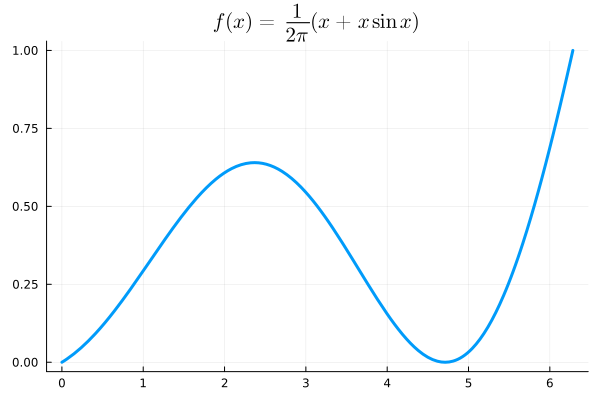

In [2]:
a, b = 0, 2π
f = x -> x * ( 1 + sin(x) ) /( 2π )
df_max = 1 + 1/(2π)

# maximum of |f''|, |f'''|, |f''''| on [a,b] (computed on a fine grid)
d2f = x -> ( 2cos(x) - x * sin(x) ) /( 2π )
d3f = x -> ( -3sin(x) - x * cos(x) ) /( 2π )
d4f = x -> ( -4cos(x) + x * sin(x) ) /( 2π )
X = range(a, b, 10^5)
d2f_max = maximum( abs.( d2f.(X) ) )
d3f_max = maximum( abs.( d3f.(X) ) )
d4f_max = maximum( abs.( d4f.(X) ) )
plot( f, a, b, title=L"f(x) = \frac{1}{2\pi} (x + x\sin x ) ", lw = 3, legend=false)

## Rectangular rule

The simplest rule of this kind is taking $X = \{a\}$ and considering the polynomial interpolation of degree $0$: $p_0(x) = f(a)$,

$$
\begin{align}
    \int_a^b f(x)\mathrm{d}x &\approx \int_a^b p_0(x)\mathrm{d}x \nonumber\\
    &= (b-a) f(a).
\end{align}
$$ {#eq-rectangular}

The rule has weights $\{ b-a \}$ and nodes $\{ a \}$. Notice that this rule is exact if $f$ is a polynomial of degree $0$.

::: {#exr-l10-mvt name="Interpolation error with one node"}

[](../exercises/bank.html#bank-exr-l10-mvt)

Write down the interpolation error formula for $f - p$ when $p$ interpolates $f$ on $n+1$ nodes (@thm-Lagrange-interpolation). What does it say when $n = 0$ and $X = \{a\}$?

::: {.exercise-solution style="display: none;"}

We have: for $x$, there exists $\xi_x$ between $\min\{ x, \min X\}$ and $\max\{x,\max X\}$ such that 

\begin{align}
f(x) - p(x) &= \frac{f^{(n+1)}(\xi_x)}{(n+1)!} \ell_X(x)
\end{align}

where $\ell_X$ is the node polynomial on $X$. For $n = 0$ and $X = \{a\}$, $p = f(a)$ and this reads $f(x) - f(a) = f'(\xi_x)(x - a)$ for some $\xi_x$ between $a$ and $x$ (which is just the mean value theorem)

:::

:::

::: {#exr-l10-rectangular-error name="Error estimate"}

[](../exercises/bank.html#bank-exr-l10-rectangular-error)

Suppose $f \in C^1([a,b])$. Show that

$$
\begin{align}
    \left| \int_{a}^b f - (b-a) f(a) \right| \leq \| f'\|_{L^\infty([a,b])} \frac{(b-a)^2}{2}.
\end{align}
$$

::: {.exercise-solution style="display: none;"}

Since $p_0$ is a degree zero interpolating polynomial, we may apply the error bound we had for interpolation (@thm-Lagrange-interpolation): 

$$
\begin{align}
    f(x) - p_0(x) = f'(\xi_x) (x - a) 
\end{align}
$$

for some $\xi_x \in [a, x]$ (in this case, this is just the mean value theorem). Therefore, integrating this over $[a,b]$, we have the bound

$$
\begin{align}
    \left| \int_{a}^b \big[ f(x) - p_0(x) \big] \mathrm{d}x \right| 
    %
    &\leq \| f'\|_{L^\infty([a,b])} \int_a^b |x - a| \mathrm{d}x \nonumber\\
    &= \| f'\|_{L^\infty([a,b])} \int_{0}^{b-a} t \,\mathrm{d}t \nonumber\\
    %
    &= \| f'\|_{L^\infty([a,b])} \frac{(b-a)^2}{2}. \nonumber
\end{align}
$$

:::

:::

***Composite rule.*** This error bound is only useful if $[a,b]$ is a small interval (or $f'$ is small). It therefore makes sense to split the interval $[a,b]$ into $n$ subintervals and consider the rectangular rule on each one: consider $x_j = a + j\frac{b-a}{n}$ for $j = 0,\dots,n$ and write

$$
\begin{align}
    \int_a^b f &= \sum_{j=0}^{n-1} \int_{x_j}^{x_{j+1}} f \nonumber\\
    %
    &\approx \sum_{j=0}^{n-1} (x_{j+1} - x_j) f(x_j). 
\end{align}
$$

This is a quadrature rule with weights $w_j = x_{j+1} - x_j = \frac{b-a}{n}$ and nodes $x_j$ for $j = 0,\dots,n-1$. 

::: {#exr-l10-riemann}

[](../exercises/bank.html#bank-exr-l10-riemann)

Approximate $\int_0^1 x \,\mathrm{d}x$ by the composite rectangular rule with $n$ subintervals of equal length. What is the error?

::: {.exercise-solution style="display: none;"}

First, note that $\int_0^1 x \mathrm{d}x = \frac12$.

The composite rectangular rule on $[0,1]$ is $\frac1n \sum_{j=0}^{n-1} \frac{j}{n} = \frac{n-1}{2n} = \frac12 - \frac{1}{2n}$, so the error is exactly $\frac{1}{2n}$: the rate $O(n^{-1})$ of @thm-rectangular-composite (and the constant $\frac{\|f'\|_{L^\infty}}{2}(b-a)^2 = \frac12$ is attained).

:::

:::

::: {#thm-rectangular-composite}

Suppose $f \in C^1([a,b])$. Then the composite rectangular rule satisfies

$$
\begin{align}
    \left| \int_a^b f - \sum_{j=0}^{n-1} \frac{b-a}{n} f(x_j) \right| &\leq   \frac{\| f'\|_{L^\infty([a,b])}}{2} \frac{ (b-a)^2 }{ n }.
\end{align}
$$

:::

::: {.proof}
Using @exr-l10-rectangular-error on each subinterval $[x_j, x_{j+1}]$ and summing over $j$, we obtain

$$
\begin{align}
    \left| \int_a^b f - \sum_{j=0}^{n-1} \frac{b-a}{n} f(x_j) \right| &\leq  \| f'\|_{L^\infty([a,b])} \sum_{j=0}^{n-1} \frac12 \Big(\frac{b-a}{n}\Big)^2 \nonumber\\
    %
    &=   \frac{\| f'\|_{L^\infty([a,b])}}{2} \frac{ (b-a)^2 }{ n }. \nonumber
\end{align}
$$
:::

::: {#rem-rectangular-exact}
Notice that this quadrature rule is exact if $f$ is a polynomial of degree $0$.
:::

***Numerics.*** We now test this numerically:

Plots.AnimatedGif("C:\\Users\\jack6\\Projects\\Math5485-Fall-2026\\images\\Rectangular.gif")
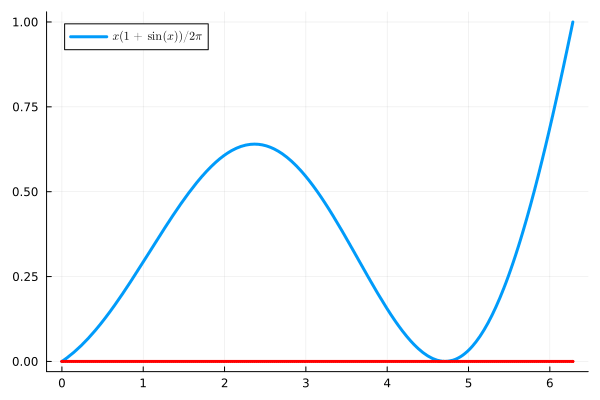

In [3]:
N = 50
R = []

anim = @animate for n ∈ 1:N
    
    h = (b-a)/n
    x = [a + j*(b-a)/n for j in 0:n]
    
    push!( R, sum( [ ( x[j+1] - x[j] ) * f( x[j] ) for j in 1:n] ) )
    
    plot( f, a, b, label=L"x( 1 + \sin(x) )/2π", lw = 3)

    for m ∈ 1:n 
        plot!([x[m], x[m+1]], [f(x[m]), f(x[m])], lw=3, color="red", primary=false)
        plot!([x[m], x[m]], [0, f(x[m])], lw=3, color="red", primary=false)
        plot!([x[m+1], x[m+1]], [0, f(x[m])], lw=3, color="red", primary=false)
    end

end

gif(anim, "../images/Rectangular.gif", fps = 1, show_msg = false)

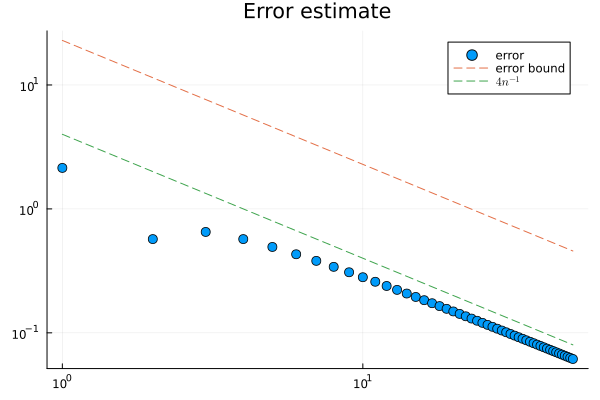

In [4]:
scatter( abs.(R .- (π -1)), xaxis=:log, yaxis=:log, markersize=5, label="error", title="Error estimate" )
plot!( (1/2)*df_max*(b-a)^2*(1:N).^(-1), linestyle=:dash,label="error bound" )

plot!( 4*(1:N).^(-1), linestyle=:dash, label=L"4n^{-1}" )

We can see here that the error decays with rate $O(n^{-1})$ and the error bound (proved above) is in fact an upper bound!

## Trapezoid rule

The next simplest rule of this kind is taking $X = \{a, b\}$ and considering the polynomial interpolation $p_1$ of degree $1$:

$$
\begin{align}
    \int_a^b f(x) \mathrm{d}x 
    %
    &\approx \int_a^b p_1(x) \mathrm{d}x \nonumber\\
    %
    &= \frac{b-a}{2} \big( f(a) + f(b) \big).
\end{align}
$$

When $f(a), f(b) \geq 0$, this is the area of the trapezium with vertices $(a,0), (a,f(a)), (b, f(b)), (b,0)$: width $b-a$ times the average height $\frac{f(a) + f(b)}{2}$.

This rule has weights $\{ \frac{b-a}{2}, \frac{b-a}{2} \}$ and nodes $\{ a, b \}$. Notice that this rule is exact if $f$ is a polynomial of degree $1$ (because $f$ agrees with $p_1$ in this case).

::: {#exr-l10-trapezoid-rule}

[](../exercises/bank.html#bank-exr-l10-trapezoid-rule)

1. Write down the polynomial $p_1$ of degree at most $1$ interpolating $f$ on $X = \{a, b\}$.
2. Show that $\int_a^b p_1(x) \,\mathrm{d}x = \frac{b-a}{2} \big( f(a) + f(b) \big)$.

::: {.exercise-hint style="display: none;"}

You can either go through the details in the integration, or draw a picture and calculate the area of the trapezium with points $(a,0), (a,f(a)), (b, f(b)), (b,0)$. If you do the integration explicitly, the Newton form is probably slightly easier...

:::

::: {.exercise-solution style="display: none;"}

*Lagrange form*:

1. We have $p_1(x) = \frac{x-b}{a-b}f(a) + \frac{x-a}{b-a} f(b)$.

2. We have
$$
\begin{align}
    \int_a^b \frac{x-b}{a-b} \,\mathrm{d}x 
    %
    &= \frac{1}{a-b} \Big[ \frac{(x-b)^2}{2} \Big]_a^b 
    %
    \nonumber\\
    %
    &= - \frac{(a-b)^2}{2(a-b)} = \frac{b-a}{2}
    \nonumber\\
    \int_a^b \frac{x-a}{b-a} \,\mathrm{d}x &= \frac{1}{b-a} \Big[ \frac{(x-a)^2}{2} \Big]_a^b 
    \nonumber\\
    &= \frac{b-a}{2}, \nonumber
\end{align}
$$
and so $\int_a^b p_1 = \frac{b-a}{2} f(a) + \frac{b-a}{2} f(b)$. 

*Newton form*:

1. $p_1(x) = f(a) + \frac{f(b)-f(a)}{b-a} (x-a)$, 
2. Integrating gives 
$$
\begin{align}
    \int_a^b (x-a) \mathrm{d}x &= \frac12 (x-a)^2\Big|_a^b \nonumber\\
    %
    &= \frac12 (b-a)^2
\end{align}
$$
and the result follows.

:::

:::

::: {#exr-l10-node-sign}

[](../exercises/bank.html#bank-exr-l10-node-sign)

What is the sign of $(x-a)(x-b)$ on $[a,b]$? Compute $\int_a^b |(x-a)(x-b)| \,\mathrm{d}x$.

::: {.exercise-hint style="display: none;"}

Make the substitution $t := x - \frac{a+b}{2}$ and define $h := b-a$.

:::

::: {.exercise-solution style="display: none;"}

We have $(x-a)(x-b) \leq 0$ on $[a,b]$, so 

\begin{align}
\int_a^b |(x-a)(x-b)| \,\mathrm{d}x 
%
&= -\int_a^b (x-a)(x-b) \,\mathrm{d}x \nonumber\\
%
&= \int_{-h/2}^{h/2} \big( \tfrac{h^2}{4} -t^2 \big) \mathrm{d}t \nonumber\\
%
&= \tfrac{h^3}{4} - \Big[ \frac{t^3}{3} \Big]_{-h/2}^{h/2} \nonumber\\
%
&= \tfrac{h^3}{4} - \frac{h^3}{12}
\nonumber\\
%
&= \frac{(b-a)^3}{6}.
\end{align}

:::

:::

::: {#thm-trapezoid-error name="Error estimate"}

Suppose $f \in C^2([a,b])$. Then

$$
\begin{align}
    \left| \int_{a}^b f - \frac{b-a}{2} \big( f(a) + f(b) \big) \right| \leq \frac{\| f''\|_{L^\infty([a,b])}}{12} (b-a)^3.
\end{align}
$$

:::

::: {.proof}
Since $p_1$ is a degree one interpolating polynomial, we may apply the error bound we had for interpolation (@thm-Lagrange-interpolation): 

$$
\begin{align}
    f(x) - p_1(x) = \frac{f''(\xi_x)}{2} (x - a)(x-b) 
\end{align}
$$

for some $\xi_x \in [a, b]$. Therefore, integrating this over $[a,b]$, we have the bound

$$
\begin{align}
    \left| \int_{a}^b \big[ f(x) - p_1(x) \big] \mathrm{d}x \right| 
    %
    &\leq \frac{\| f''\|_{L^\infty([a,b])}}{2} \int_a^b |(x - a)(x-b)| \mathrm{d}x \nonumber\\
    &= \frac{\| f''\|_{L^\infty([a,b])}}{2} \frac{(b-a)^3}{6} \nonumber
\end{align}
$$

(see @exr-l10-node-sign for the last integral).
:::

***Composite rule.*** This error bound is only useful if $[a,b]$ is a small interval (or $f''$ is small). It therefore makes sense to split the interval $[a,b]$ into $n$ subintervals and consider the trapezium rule on each one: consider $x_j = a + j\frac{b-a}{n}$ for $j = 0,\dots,n$ and write

$$
\begin{align}
    \int_a^b f(x) \mathrm{d}x &= \sum_{j=0}^{n-1} \int_{x_j}^{x_{j+1}} f(x)\mathrm{d}x \nonumber\\
    %
    &\approx \sum_{j=0}^{n-1} \frac{x_{j+1} - x_j}{2} \big[ f(x_j) + f(x_{j+1}) \big].
\end{align}
$$

This is a quadrature rule with weights $w_0 = w_n = \frac{x_{1} - x_0}{2} = \frac{b-a}{2n}$ and $w_j = \frac{b-a}{n}$ for $j=1,\dots,n-1$. 

::: {#thm-trapezoid-composite}

Suppose $f \in C^2([a,b])$. Then the composite trapezoid rule satisfies

$$
\begin{align}
    \left| \int_a^b f - \frac{b-a}{n} {\sum_{0 \leq j \leq n}}^\prime f(x_j) \right| &\leq   \frac{\| f''\|_{L^\infty([a,b])}}{12} \frac{ (b-a)^3 }{ n^2 }
\end{align}
$$

where $\sum^\prime$ indicates that the first and last terms must be multiplied by $\frac12$.

:::

::: {.proof}
Using @thm-trapezoid-error on each subinterval and summing over $j$, we obtain

$$
\begin{align}
    \left| \int_a^b f - \frac{b-a}{n} {\sum_{0 \leq j \leq n}}^\prime f(x_j) \right| &\leq  \| f''\|_{L^\infty([a,b])} \sum_{j=0}^{n-1} \frac1{12} \left(\frac{b-a}{n}\right)^3 \nonumber\\
    %
    &=   \frac{\| f''\|_{L^\infty([a,b])}}{12} \frac{ (b-a)^3 }{ n^2 }. \nonumber
\end{align}
$$
:::

::: {#rem-trapezoid-exact}
Notice that this quadrature rule is exact if $f$ is a polynomial of degree $1$.
:::

***Numerics.*** We now test this numerically:

Plots.AnimatedGif("C:\\Users\\jack6\\Projects\\Math5485-Fall-2026\\images\\Trapezium.gif")
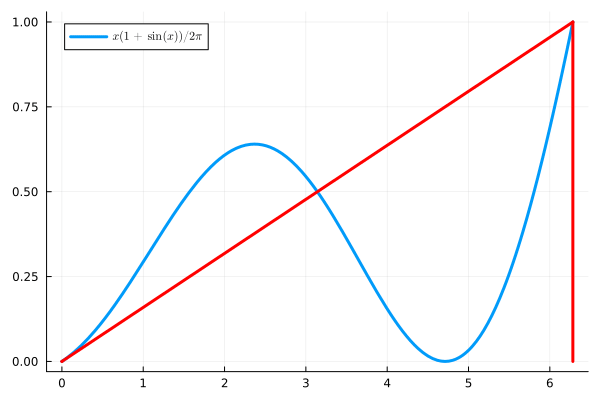

In [5]:
N = 30
T = []

anim = @animate for n ∈ 1:N
    
    h = (b-a)/n
    x = [a + j*(b-a)/n for j in 0:n]
    
    push!( T, sum( [ (1/2)*( x[j+1] - x[j] ) * ( f(x[j]) + f(x[j+1]) ) for j in 1:n] ) )
    
    plot( f, a, b, label=L"x( 1 + \sin(x) )/2π", lw = 3)

    for m ∈ 1:n 
        plot!([x[m], x[m+1]], [f(x[m]), f(x[m+1])], lw=3, color="red", primary=false)
        plot!([x[m], x[m]], [0, f(x[m])], lw=3, color="red", primary=false)
        plot!([x[m+1], x[m+1]], [0, f(x[m+1])], lw=3, color="red", primary=false)
    end

end

gif(anim, "../images/Trapezium.gif", fps = 1, show_msg = false)

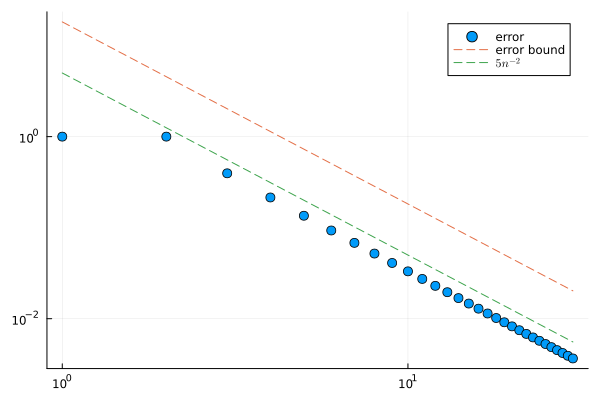

In [6]:
scatter( abs.(T .- (π -1)), xaxis=:log, yaxis=:log, markersize=5, label="error" )
plot!( (1/12)*d2f_max*(b-a)^3*(1:N).^(-2), linestyle=:dash, label="error bound" )
plot!( 5*(1:N).^(-2), linestyle=:dash, label=L"5n^{-2}" )  

We can see here that the error decays with rate $O(n^{-2})$ and the error bound (proved above) is in fact an upper bound!

## Summary

1. Rectangular rule is given by $(b-a) f(a)$ and leads to a composite rule with error $C \|f'\|_{L^\infty([a,b])} n^{-1}$ (@thm-rectangular-composite),
2. Trapezium rule is given by $\frac{b-a}{2} \left( f(a) + f(b) \right)$ and leads to a composite rule with error $C \|f''\|_{L^\infty([a,b])} n^{-2}$ (@thm-trapezoid-composite).

## Next time....

- Simpson's rule: integrating the quadratic interpolant on $\{a, \tfrac{a+b}{2}, b\}$,
- Simpson's rule is exact for cubics, and an improved error estimate using Hermite interpolation.

::: {.callout-tip}
# TO-DO

* Exercises throughout the notes,
* (Sign-up to office hours if you like)

:::

## Extra exercises

::: {#exr-l10-midpoint name="Midpoint rule"}

[](../exercises/bank.html#bank-exr-l10-midpoint)

The *midpoint rule* is $\int_a^b f \approx (b-a) f\big(\tfrac{a+b}{2}\big)$.

1. Show that the midpoint rule is exact for all polynomials of degree at most $1$.
2. Suppose $f \in C^2([a,b])$. Show that
$$
    \left| \int_a^b f - (b-a) f\big(\tfrac{a+b}{2}\big) \right| \leq \frac{\|f''\|_{L^\infty([a,b])}}{24} (b-a)^3.
$$
3. Write down the composite midpoint rule on $n$ subintervals of equal length and show that its error is bounded by $\frac{\|f''\|_{L^\infty([a,b])}}{24} \frac{(b-a)^3}{n^2}$. Compare with @thm-trapezoid-composite.

::: {.exercise-hint style="display: none;"}

For 2, use Taylor's theorem about $m = \frac{a+b}{2}$: 

\begin{align}
    f(x) = f(m) + f'(m)(x - m) + \frac{f''(\xi_x)}{2}(x-m)^2.
\end{align}

:::

::: {.exercise-solution style="display: none;"}

Let $m = \frac{a+b}{2}$.

1. For $f = 1$: $\int_a^b 1 = b - a = (b-a) \cdot 1$. For $f = x - m$: 
$$
\begin{align}
    \int_a^b (x - m) \,\mathrm{d}x &= 0 
    \nonumber\\
    %
    &= (b-a)(m - m).
\end{align}
$$

1. By Taylor's theorem, 
$$
\begin{align}
    f(x) = f(m) + f'(m)(x-m) + \frac{f''(\xi_x)}{2} (x-m)^2
\end{align}
$$ 
for some $\xi_x$ between $m$ and $x$. Integrating and using $\int_a^b (x - m) \,\mathrm{d}x = 0$,
$$
\begin{align}
    \left| \int_a^b f - (b-a) f(m) \right| 
    %
    &= \left| \int_a^b \frac{f''(\xi_x)}{2} (x-m)^2 \,\mathrm{d}x \right| \nonumber\\
    %
    &\leq \frac{\|f''\|_{L^\infty([a,b])}}{2} \int_a^b (x - m)^2 \,\mathrm{d}x 
    \nonumber\\
    %
    &= \frac{\|f''\|_{L^\infty([a,b])}}{2} \frac{(b-a)^3}{12}.
\end{align}
$$

1. With $x_j = a + j \frac{b-a}{n}$, the composite rule is $\frac{b-a}{n} \sum_{j=0}^{n-1} f\big( \frac{x_j + x_{j+1}}{2} \big)$. Applying 2 on each subinterval of length $\frac{b-a}{n}$ and summing the $n$ errors gives
$$
\begin{align}
    n \cdot \frac{\|f''\|_{L^\infty([a,b])}}{24} \Big( \frac{b-a}{n} \Big)^3 
    %
    &= \frac{\|f''\|_{L^\infty([a,b])}}{24} \frac{(b-a)^3}{n^2}.
\end{align}
$$
This is the same rate $O(n^{-2})$ as the composite trapezoid rule, but with half the constant (and one fewer function evaluation).

:::

:::

::: {#exr-l10-weights name="Properties of interpolatory weights" .difficult}

[](../exercises/bank.html#bank-exr-l10-weights)

Let $x_0, \dots, x_n \in [a,b]$ be distinct and let $w_j = \int_a^b \ell_j$ be the weights in @eq-interpolatory-quadrature.

1. Show that $\{w_j\}$ are the *unique* weights for which $\sum_{j=0}^n w_j f(x_j)$ is exact for all $f \in \mathcal P_n$.
2. Show that $\sum_{j=0}^n w_j = b - a$.
3. Let $\hat x_j \in [0,1]$ and let $\hat w_j$ be the corresponding weights on $[0,1]$. Show that the nodes $x_j = a + (b-a) \hat x_j$ on $[a,b]$ have weights $w_j = (b-a) \hat w_j$.
4. Suppose the nodes are symmetric: $x_{n-j} = a + b - x_j$ for all $j$. Show that $w_{n-j} = w_j$.

::: {.exercise-hint  style="display: none;"}

1. What happens if you apply the rule to $f(x) = \ell_j(x)$?
2. What happens if you apply the rule to $f(x) = 1$?
3. Use $w_j = \int_a^b \ell_j$,
4. Show that $\ell_{n-j}(x) = \ell_j(a + b - x)$ by checking the values of both sides at the nodes.

:::

::: {.exercise-solution style="display: none;"}

1. If $f \in \mathcal P_n$ then $f$ is its own interpolant, $f = \sum_j \ell_j f(x_j)$, and so $\int_a^b f = \sum_j w_j f(x_j)$ and the rule is exact. Conversely, if $\sum_j v_j f(x_j)$ is exact on $\mathcal P_n$, then applying it to $\ell_j \in \mathcal P_n$ gives $v_j = \sum_k v_k \ell_j(x_k) = \int_a^b \ell_j = w_j$, as required.

2. Apply 1 to $f = 1$: $b - a = \int_a^b 1 = \sum_j w_j$.

3. Write $x = a + (b-a) t$. Since $x - x_j = (b-a)(t - \hat x_j)$, we have
$$
\begin{align}
    \ell_j(x) &= \prod_{k \not= j} \frac{x - x_k}{x_j - x_k} 
    \nonumber\\
    %
    &= \prod_{k\not=j} \frac{t - \hat x_k}{\hat x_j - \hat x_k} 
    \nonumber\\
    %
    &= \hat \ell_j(t).
\end{align}
$$
Therefore 
$$
\begin{align}
    w_j = \int_a^b \ell_j(x) \,\mathrm{d}x = (b-a) \int_0^1 \hat\ell_j(t) \,\mathrm{d}t = (b-a) \hat w_j.
\end{align}
$$

1. Let $q(x) := \ell_j(a + b - x) \in \mathcal P_n$. Then $q(x_{n-k}) = \ell_j(x_k) = \delta_{jk}$. That is, $q(x_k) = \delta_{k, n-j}$, so $q = \ell_{n-j}$. Substituting $y = a + b - x$,
$$
\begin{align}
    w_{n-j} &= \int_a^b \ell_j(a+b-x) \,\mathrm{d}x \nonumber\\
    %
    &= \int_a^b \ell_j(y) \,\mathrm{d}y \nonumber\\
    %
    &= w_j.
\end{align}
$$

:::

:::